# Decision Tree — Beginner Student Demo

This notebook shows how a **Decision Tree Classifier** is executed from start to finish.

### Learning Goals
1. Load and inspect a dataset
2. Identify features **X** and target **y**
3. Split training and testing data
4. Train a Decision Tree
5. Make predictions
6. Evaluate accuracy and confusion matrix
7. Visualize the actual tree
8. Compare Gini and Entropy
9. See why `max_depth` can help control overfitting

We will use the built-in **Iris flower dataset**, so no CSV download is required.

## Problem

Use four flower measurements to predict one of three Iris species:

- Setosa
- Versicolor
- Virginica

> **Question:** Can a Decision Tree predict the flower species from its measurements?

## Step 1 — Import Libraries

In [16]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2 — Load the Dataset

**X = features/clues given to the model**  
**y = target/answer the model tries to learn**

In [17]:
iris = load_iris()
X = iris.data
y = iris.target

print("Features:", iris.feature_names)
print("Classes:", iris.target_names)
print("Number of samples:", len(X))

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Number of samples: 150


## Step 3 — Inspect the Data

In [18]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


## Step 4 — Train/Test Split

- **80% training** → model studies these examples
- **20% testing** → unseen examples used for evaluation
- `stratify=y` → keeps class proportions similar
- `random_state=42` → makes the split reproducible

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


## Step 5 — Create the Decision Tree

`criterion="gini"` tells the model to use **Gini Impurity**.

`max_depth=3` limits how deep the tree can grow.

In [20]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

print(model)

DecisionTreeClassifier(max_depth=3, random_state=42)


## Step 6 — Train

`.fit()` is the **learning stage**.

In [21]:
model.fit(X_train, y_train)
print("Training complete!")

Training complete!


## Step 7 — Predict

`.predict()` asks the trained model to classify **unseen test samples**.

In [22]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": [iris.target_names[i] for i in y_test],
    "Predicted": [iris.target_names[i] for i in y_pred]
})

comparison.head(10)

,Actual,Predicted
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


## Step 8 — Accuracy

In [23]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.967
Accuracy Percentage: 96.67 %


## Step 9 — Confusion Matrix

Diagonal values = correct predictions.  
Off-diagonal values = mistakes.

In [24]:
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=iris.target_names,
    columns=iris.target_names
)

cm_df

,setosa,versicolor,virginica
setosa,10,0,0
versicolor,0,9,1
virginica,0,0,10


## Step 10 — Precision, Recall, and F1-Score

In [25]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Step 11 — Visualize the Decision Tree

Read the tree from the **root node at the top** until you reach a **leaf node**.

Inside a node:

- feature condition = question
- `gini` = mixedness
- `samples` = training examples in the node
- `value` = number from each class
- `class` = predicted class

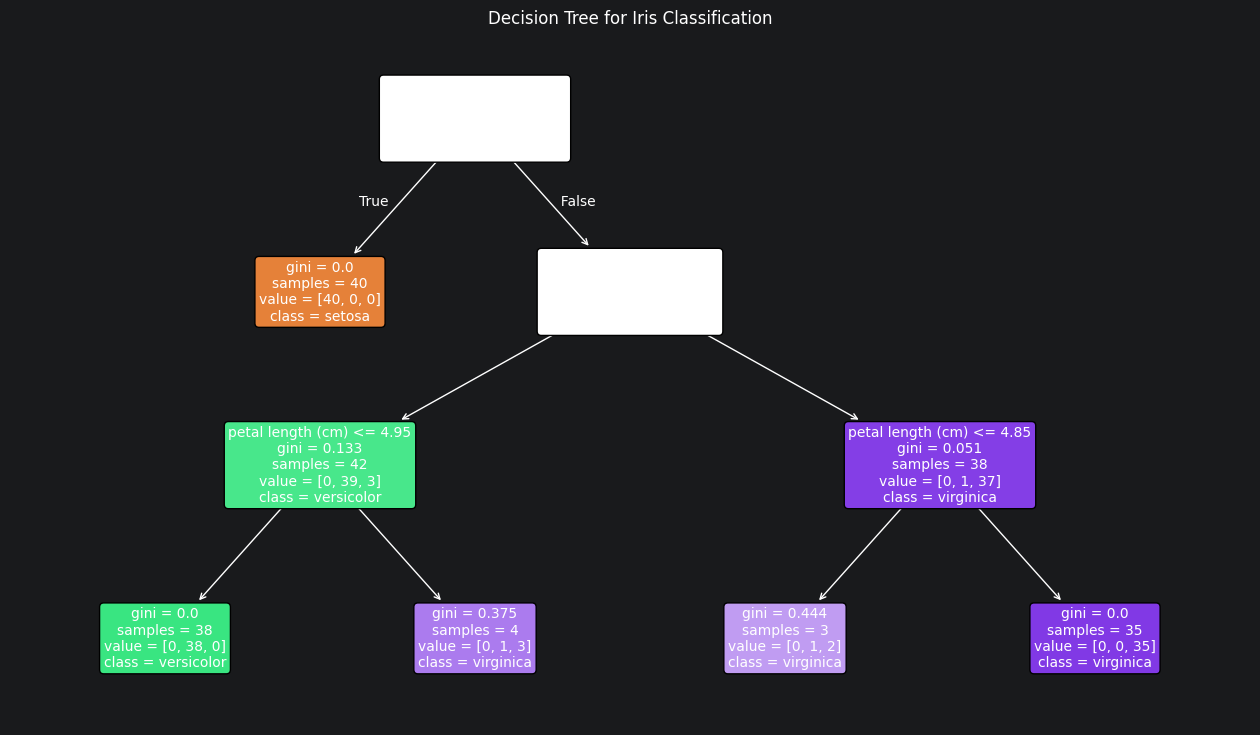

In [26]:
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Classification")
plt.show()

### Remember

> **Lower Gini = purer group**

If `gini = 0`, all training samples in that node belong to one class.

## Step 12 — Feature Importance

In [27]:
importance_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df

,Feature,Importance
2,petal length (cm),0.579077
3,petal width (cm),0.420923
1,sepal width (cm),0.000000
0,sepal length (cm),0.000000


## Step 13 — Predict a New Flower

In [28]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)[0]

print("Predicted species:", iris.target_names[prediction])

Predicted species: setosa


# Step 14 — Use Entropy Instead of Gini

Change the criterion to:

`criterion="entropy"`

The tree will now use **Entropy-based split evaluation**.

In [29]:
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42
)

entropy_model.fit(X_train, y_train)
entropy_pred = entropy_model.predict(X_test)

print(
    "Entropy Tree Accuracy:",
    round(accuracy_score(y_test, entropy_pred), 3)
)

Entropy Tree Accuracy: 0.967


## Visualize the Entropy Tree

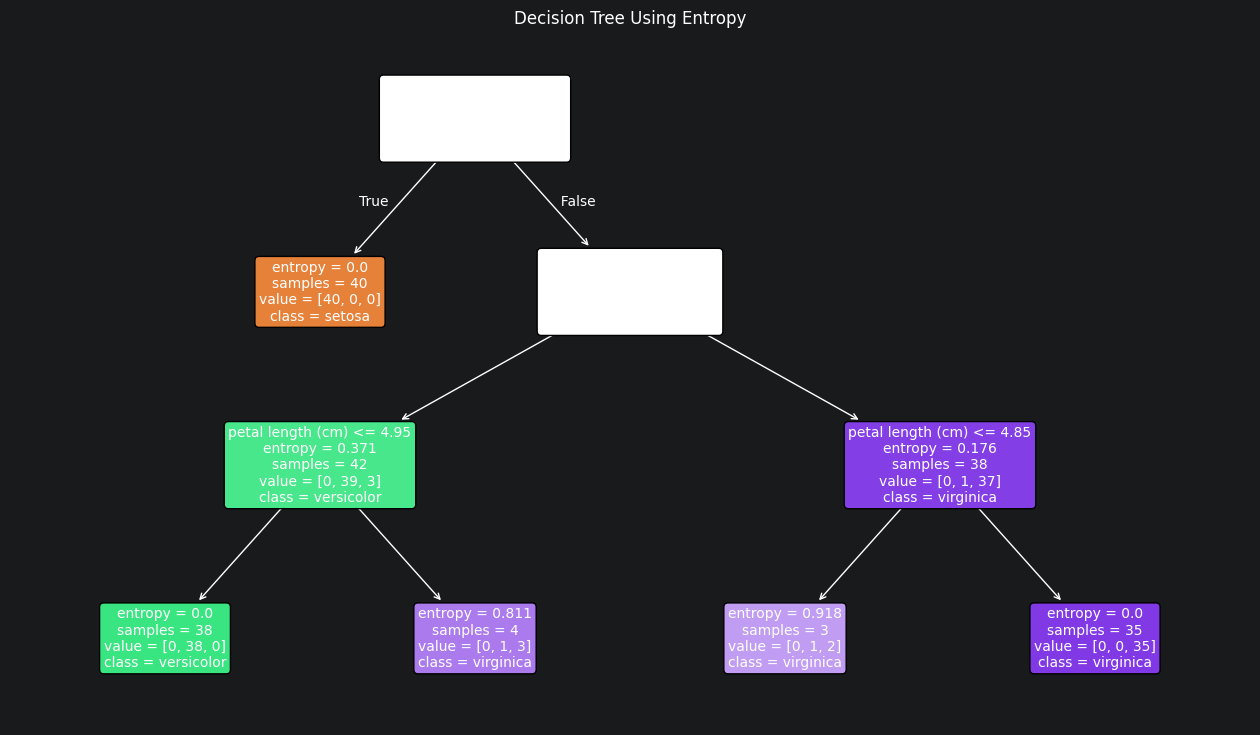

In [30]:
plt.figure(figsize=(16, 9))

plot_tree(
    entropy_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Using Entropy")
plt.show()